# MLB Player Salary Prediction Using XGBoost (2015–2024)

**Project Overview.** This project uses XGBoost to predict MLB player salaries based on player statistics from 2015 to 2024. It also compares models using all features and selected features to see how feature selection affects prediction accuracy.

**Model Training.** For each year, the data is split into 80% for training and 20% for testing, with a random state of 234. Grid search with 5-fold cross-validation is used to find the best parameters. Feature selection is also carried out using cross-validation on the training data.

**Limitations** The models are trained and tested separately for each year, so the results do not show how well they can predict salaries in future seasons. The test data is only used to evaluate the final models.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

years = list(range(2015, 2025))
data_dir = Path.cwd()
results_dir = Path('results')
figures_dir = Path('figures')
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
seed = 234

param_grid = {
    'n_estimators': list(range(10, 201, 10)),
    'max_depth': list(range(1, 21)),
    'learning_rate': [0.1, 0.2, 0.3],
}
print('Working directory:', Path.cwd())
print('Years:', years)

Working directory: C:\Users\User\Documents\MLB Salary Prediction
Years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## 2. Validate and load the datasets

The datasets from 2015 to 2024 are loaded and checked to make sure they have the same columns. Missing values, invalid salaries, and data types are also checked before training the models.

In [2]:
required = {'Player', 'Awards', 'Team', 'Lg', 'Salary'}
frames = {}
reference_columns = None
for year in years:
    path = data_dir / f'{year}_alldata.csv'
    if not path.exists():
        raise FileNotFoundError(f'Missing CSV: {path.resolve()}')
    raw = pd.read_csv(path)
    if not required.issubset(raw.columns):
        raise ValueError(f'{year}: missing required columns: {required - set(raw.columns)}')
    if reference_columns is None:
        reference_columns = set(raw.columns)
    if set(raw.columns) != reference_columns:
        raise ValueError(f'{year}: columns differ from first year')
    frames[year] = raw
    print(f'{year}: {len(raw)} rows, {len(raw.columns)} columns; '
          f'invalid salaries: {(pd.to_numeric(raw["Salary"], errors="coerce").isna() | (pd.to_numeric(raw["Salary"], errors="coerce") <= 0)).sum()}')

2015: 334 rows, 48 columns; invalid salaries: 0
2016: 325 rows, 48 columns; invalid salaries: 0
2017: 340 rows, 48 columns; invalid salaries: 0
2018: 330 rows, 48 columns; invalid salaries: 0
2019: 314 rows, 48 columns; invalid salaries: 0
2020: 306 rows, 48 columns; invalid salaries: 0
2021: 305 rows, 48 columns; invalid salaries: 0
2022: 305 rows, 48 columns; invalid salaries: 0
2023: 310 rows, 48 columns; invalid salaries: 0
2024: 306 rows, 48 columns; invalid salaries: 0


## 3. Data Preprocessing

Categorical variables are converted into numerical values using one-hot encoding. The training data is used to determine the encoding, and the test data follows the same columns. The Awards variable is converted into a binary variable. Standardization is not needed for XGBoost because it is a tree-based model.

In [3]:
def prepare_year(raw):
    df = raw.drop(columns=['Player']).copy()
    df['Salary'] = pd.to_numeric(df['Salary'], errors='coerce')
    valid = df['Salary'].notna() & (df['Salary'] > 0)
    if not valid.all():
        print(f'  Removing {(~valid).sum()} records with missing/nonpositive salary')
    df = df.loc[valid].copy()
    df['Awards'] = df['Awards'].notna().astype(int)
    train, test = train_test_split(df, test_size=0.2, random_state=seed)
    y_train = np.log(train['Salary'])
    y_test = np.log(test['Salary'])
    X_train = pd.get_dummies(train.drop(columns=['Salary']), columns=['Team', 'Lg'], drop_first=True, dtype=int)
    X_test = pd.get_dummies(test.drop(columns=['Salary']), columns=['Team', 'Lg'], drop_first=True, dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
    # Convert all remaining fields to numeric; fail on unexpected strings/missing values.
    for col in X_train.columns:
        X_train[col] = pd.to_numeric(X_train[col], errors='raise')
        X_test[col] = pd.to_numeric(X_test[col], errors='raise')
    if X_train.isna().any().any() or X_test.isna().any().any():
        raise ValueError('Missing predictor values detected; inspect the CSV before proceeding.')
    return X_train, X_test, y_train, y_test


def evaluate(model, X_test, y_test):
    predicted_log = model.predict(X_test)
    actual_salary = np.exp(y_test.to_numpy())
    predicted_salary = np.exp(predicted_log)
    return {
        'Test_R2_logSalary': r2_score(y_test, predicted_log),
        'Test_MAE_logSalary': mean_absolute_error(y_test, predicted_log),
        'Test_MSE_logSalary': mean_squared_error(y_test, predicted_log),
        'Test_RMSE_logSalary': np.sqrt(mean_squared_error(y_test, predicted_log)),
        'Test_MAE_Salary': mean_absolute_error(actual_salary, predicted_salary),
        'Test_RMSE_Salary': np.sqrt(mean_squared_error(actual_salary, predicted_salary)),
        'Test_MAPE_Salary_pct': np.mean(np.abs((actual_salary - predicted_salary) / actual_salary)) * 100,
    }

## 4. Train and tune the full-feature XGBoost model

GridSearchCV is used to find the best parameters for the XGBoost model using all available features. The models are evaluated using mean squared error (MSE) on log-transformed salaries during cross-validation.

In [4]:
def tune_full_model(X_train, y_train):
    estimator = XGBRegressor(objective='reg:squarederror', random_state=seed, n_jobs=1)
    search = GridSearchCV(
        estimator=estimator, param_grid=param_grid, cv=5,
        scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
    search.fit(X_train, y_train)
    return search

## 5. Select the number of features using 5-fold CV

5-fold cross-validation is used to find the best number of features for each year. In each fold, features are ranked based on the training data, and the model is evaluated on the validation data using different numbers of features. The XGBoost parameters remain the same during this process.

After selecting the best number of features, the model is trained again using the full training dataset with the selected features.

In [5]:
def select_feature_count(X_train, y_train, best_params):
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)
    n_features = X_train.shape[1]
    scores = np.empty((5, n_features))
    for fold, (tr_idx, val_idx) in enumerate(kfold.split(X_train)):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        ranker = XGBRegressor(objective='reg:squarederror', random_state=seed, n_jobs=1, **best_params)
        ranker.fit(X_tr, y_tr)
        ranked = pd.Series(ranker.feature_importances_, index=X_tr.columns).sort_values(ascending=False).index
        for k in range(1, n_features + 1):
            chosen = ranked[:k].tolist()
            model = clone(ranker)
            model.fit(X_tr[chosen], y_tr)
            scores[fold, k - 1] = r2_score(y_val, model.predict(X_val[chosen]))
    results = pd.DataFrame({
        'k': np.arange(1, n_features + 1),
        'CV_R2': scores.mean(axis=0),
        'CV_R2_STD': scores.std(axis=0),})
    best_k = int(results.loc[results['CV_R2'].idxmax(), 'k'])
    return results, best_k

## 6. Run Models for All Years

The models are trained and evaluated separately for each year from 2015 to 2024. The results are saved as CSV files and figures, along with a summary table comparing model performance across years.

In [6]:
all_results = []
all_parameters = []
all_importances = []

for year in years:
    print(f'\n========== {year} ==========')
    X_train, X_test, y_train, y_test = prepare_year(frames[year])
    print('Training rows:', len(X_train), 'Test rows:', len(X_test), 'Features:', X_train.shape[1])

    search = tune_full_model(X_train, y_train)
    best_params = search.best_params_
    full_model = search.best_estimator_
    full_metrics = evaluate(full_model, X_test, y_test)
    print('Best parameters:', best_params)
    print('Full-model test R² (log salary):', round(full_metrics['Test_R2_logSalary'], 4))

    importance = pd.Series(full_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    for feature, value in importance.items():
        all_importances.append({'Year': year, 'Feature': feature, 'Importance': float(value)})

    cv_results, best_k = select_feature_count(X_train, y_train, best_params)
    cv_results.to_csv(results_dir / f'feature_selection_cv_{year}.csv', index=False)
    selected_features = importance.index[:best_k].tolist()
    selected_model = XGBRegressor(objective='reg:squarederror', random_state=seed,
                                  n_jobs=1, **best_params)
    selected_model.fit(X_train[selected_features], y_train)
    selected_metrics = evaluate(selected_model, X_test[selected_features], y_test)
    print('Selected features:', best_k)
    print('Selected-model test R² (log salary):', round(selected_metrics['Test_R2_logSalary'], 4))

    for name, count, metrics in [('Full', X_train.shape[1], full_metrics),
                                 ('Selected', best_k, selected_metrics)]:
        all_results.append({'Year': year, 'Model': name, 'Features': count,
                            'Train_Rows': len(X_train), 'Test_Rows': len(X_test), **metrics})
    all_parameters.append({'Year': year, **best_params, 'Selected_k': best_k,
                           'Best_Grid_CV_Neg_MSE': search.best_score_})
    pd.Series(selected_features, name='Feature').to_csv(
        results_dir / f'selected_features_{year}.csv', index=False)

    # Feature importance figure
    top10 = importance.head(10).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5))
    top10.plot.barh(ax=ax)
    ax.set_xlabel('XGBoost feature importance (gain-based default)')
    ax.set_title(f'Top 10 Feature Importances - XGBoost ({year})')
    fig.tight_layout()
    fig.savefig(figures_dir / f'feature_importance_{year}.png', dpi=200)
    plt.close(fig)

    # CV score
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(cv_results['k'], cv_results['CV_R2'], label='Mean CV R²')
    ax.axvline(best_k, color='red', linestyle='--', label=f'Selected k={best_k}')
    ax.scatter([best_k], [cv_results.loc[cv_results['k'] == best_k, 'CV_R2'].iloc[0]], color='red')
    ax.set(xlabel='Number of Features', ylabel='Mean CV R²',
           title=f'Feature Selection Using 5-Fold CV ({year})')
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(figures_dir / f'feature_selection_{year}.png', dpi=200)
    plt.close(fig)

    # Save after each year
    pd.DataFrame(all_results).to_csv(results_dir / 'model_comparison_2015_2024.csv', index=False)
    pd.DataFrame(all_parameters).to_csv(results_dir / 'best_parameters_2015_2024.csv', index=False)
    pd.DataFrame(all_importances).to_csv(results_dir / 'feature_importances_2015_2024.csv', index=False)

comparison_df = pd.DataFrame(all_results)
display(comparison_df.round(4))


========== 2015 ==========
Training rows: 267 Test rows: 67 Features: 76
Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
Full-model test R² (log salary): 0.7128
Selected features: 33
Selected-model test R² (log salary): 0.7116

========== 2016 ==========
Training rows: 260 Test rows: 65 Features: 76
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 30}
Full-model test R² (log salary): 0.7956
Selected features: 25
Selected-model test R² (log salary): 0.8107

========== 2017 ==========
Training rows: 272 Test rows: 68 Features: 76
Best parameters: {'learning_rate': 0.3, 'max_depth': 2, 'n_estimators': 10}
Full-model test R² (log salary): 0.8311
Selected features: 12
Selected-model test R² (log salary): 0.8286

========== 2018 ==========
Training rows: 264 Test rows: 66 Features: 76
Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 30}
Full-model test R² (log salary): 0.6677
Selected features: 21
Selected-model test

,Year,Model,Features,Train_Rows,Test_Rows,Test_R2_logSalary,Test_MAE_logSalary,Test_MSE_logSalary,Test_RMSE_logSalary,Test_MAE_Salary,Test_RMSE_Salary,Test_MAPE_Salary_pct
0,2015,Full,76,267,67,0.7128,0.5207,0.5003,0.7073,2.414745e+06,4.036601e+06,57.6614
1,2015,Selected,33,267,67,0.7116,0.5155,0.5024,0.7088,2.359825e+06,3.994781e+06,57.3100
2,2016,Full,76,260,65,0.7956,0.4448,0.3681,0.6067,2.562627e+06,4.204958e+06,57.8751
3,2016,Selected,25,260,65,0.8107,0.4278,0.3409,0.5838,2.456174e+06,4.001218e+06,54.3842
4,2017,Full,76,272,68,0.8311,0.4107,0.3252,0.5702,2.202473e+06,4.015295e+06,51.5621
5,2017,Selected,12,272,68,0.8286,0.4236,0.3300,0.5745,2.334386e+06,4.149404e+06,52.9302
6,2018,Full,76,264,66,0.6677,0.5691,0.5830,0.7635,2.860755e+06,5.560800e+06,63.2897
7,2018,Selected,21,264,66,0.6612,0.5707,0.5942,0.7709,2.884098e+06,5.596641e+06,63.4209
8,2019,Full,76,251,63,0.7910,0.4589,0.4108,0.6410,2.814831e+06,5.312667e+06,50.8879
9,2019,Selected,16,251,63,0.7722,0.4651,0.4479,0.6692,2.787471e+06,5.335391e+06,51.1291


## 7. Compare annual test-set R² values

This chart compares held-out test R² on log salary, not cross-validation R².

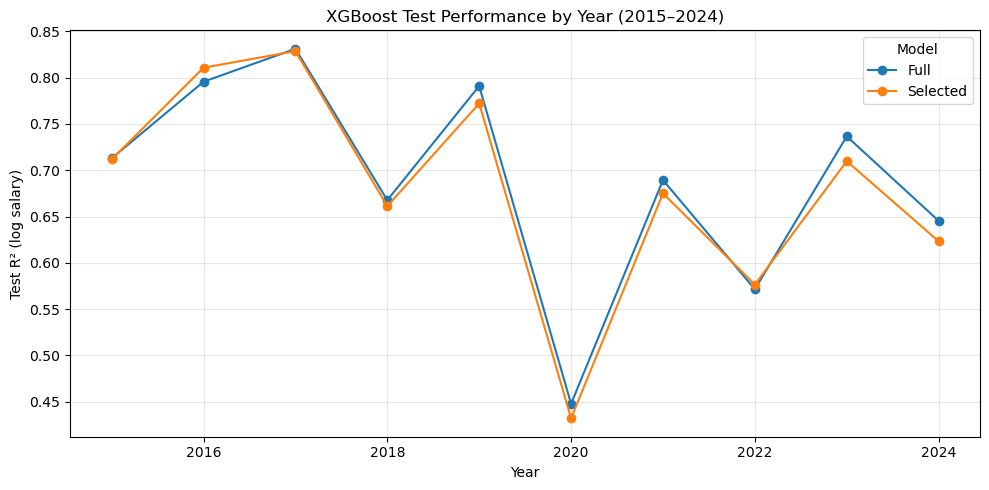

In [7]:
pivot = comparison_df.pivot(index='Year', columns='Model', values='Test_R2_logSalary')
ax = pivot.plot(marker='o', figsize=(10, 5))
ax.set(ylabel='Test R² (log salary)', title='XGBoost Test Performance by Year (2015–2024)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / 'test_r2_by_year.png', dpi=200)
plt.show()

## 8. Results and Discussion

The XGBoost models showed different prediction results across the ten years. The highest test R² was 0.8311 in 2017, while 2020 had the lowest R² of 0.4477.

Feature selection reduced the number of features used in the models, but it did not always improve prediction accuracy. In some years, the models performed better with fewer features, while in other years, using all features gave better results.

**Limitations:** The models were trained and tested using data from the same year, so the results may not reflect their ability to predict salaries in future seasons. Also, feature importance shows which variables are useful for prediction, but it does not mean they directly cause higher salaries.